# Crypto Portfolio Analytics

Refreshes local daily USD prices and market data from CoinGecko, then calculates asset correlations, constrained full-Kelly portfolio weights, performance and risk metrics against BTC, and a return-based factor model. The analyzed asset basket is configured in the `ASSETS` list in the portfolio data cell.

At run time, select a CoinGecko Demo or Pro API plan and enter its API key using hidden input. The key is not saved in the notebook. The portfolio uses long-only full-Kelly bounds of 2% minimum and 15% maximum per coin; unallocated capital is cash. Metrics use a 5% annual risk-free rate and 365 days per year.


### Refresh prices and market data from CoinGecko

Update daily USD prices plus historical market capitalization and total trading volume. Price data is saved to `data/crypto_daily_prices_usd.csv`; factor inputs are saved to `data/crypto_market_data.csv`. CoinGecko Demo requests are limited to the latest 365 days; older locally saved price data is retained.


In [51]:
# Fetch recent observations for each coin before loading prices and factor data.
from datetime import datetime, timedelta, timezone
from pathlib import Path
import pandas as pd
from getpass import getpass
import requests

api_plan = input('CoinGecko API plan (demo/pro): ').strip().lower()
if api_plan not in {'demo', 'pro'}:
    raise ValueError("Enter 'demo' or 'pro' for your CoinGecko API plan.")
api_key = getpass('CoinGecko API key (input hidden): ').strip()
if not api_key:
    raise ValueError('A CoinGecko API key is required.')
api_host = 'api.coingecko.com' if api_plan == 'demo' else 'pro-api.coingecko.com'
api_header = 'x-cg-demo-api-key' if api_plan == 'demo' else 'x-cg-pro-api-key'
headers = {api_header: api_key}
API_BASE = f'https://{api_host}/api/v3'


def coingecko_error_details(response):
    """Extract CoinGecko's safe status code/message without echoing request URLs or keys."""
    try:
        payload = response.json()
    except ValueError:
        return ''
    if isinstance(payload, dict) and payload.get('error'):
        return ' | CoinGecko error: {}'.format(payload['error'])
    status = payload.get('status', {}) if isinstance(payload, dict) else {}
    if not isinstance(status, dict):
        return ''
    code = status.get('error_code')
    message = status.get('error_message')
    if code is None and not message:
        return ''
    return ' | CoinGecko code {}: {}'.format(code or 'n/a', message or 'no message')


# Verify the key against a protected endpoint; /ping does not validate credentials.
auth_params = {}
auth_check = requests.get(
    f'{API_BASE}/simple/price',
    params={'ids': 'bitcoin', 'vs_currencies': 'usd'},
    headers=headers,
    timeout=20,
)
if auth_check.status_code == 401:
    # Some account configurations accept the documented query-key form when the header is rejected.
    query_key_name = 'x_cg_demo_api_key' if api_plan == 'demo' else 'x_cg_pro_api_key'
    try:
        query_check = requests.get(
            f'{API_BASE}/simple/price',
            params={'ids': 'bitcoin', 'vs_currencies': 'usd', query_key_name: api_key},
            timeout=20,
        )
    except requests.RequestException as exc:
        raise RuntimeError(
            f'CoinGecko credential check failed ({type(exc).__name__}); the API key was not printed.'
        ) from None
    if query_check.ok:
        auth_params = {query_key_name: api_key}
        headers = {}
    else:
        raise ValueError(
            f'CoinGecko credential check failed (HTTP {query_check.status_code}). '
            f'Confirm that the selected plan ({api_plan}) matches the key and that the key is active.'
            f'{coingecko_error_details(query_check)} The key was not printed.'
        )
elif not auth_check.ok:
    raise RuntimeError(
        f'CoinGecko credential check failed (HTTP {auth_check.status_code}).'
        f'{coingecko_error_details(auth_check)}'
    )

DATA_DIR = Path('data')
DATA_DIR.mkdir(parents=True, exist_ok=True)
PRICE_FILE = DATA_DIR / 'crypto_daily_prices_usd.csv'
MARKET_DATA_FILE = DATA_DIR / 'crypto_market_data.csv'
COIN_IDS = {
    'BTC': 'bitcoin',
    'VVV': 'venice-token',
    'HYPE': 'hyperliquid',
}
FALLBACK_START = datetime(2025, 10, 1, tzinfo=timezone.utc)
END_DATE = datetime.now(timezone.utc)
DEMO_EARLIEST_DATE = END_DATE - timedelta(days=365)
if api_plan == 'demo':
    print(
        'CoinGecko Demo history is limited to the latest 365 days. '
        'Older saved price data will be kept.'
    )

prices = pd.read_csv(PRICE_FILE, parse_dates=['date'])
prices['date'] = pd.to_datetime(prices['date'], utc=True).dt.normalize()
prices = prices.set_index('date').sort_index()
if MARKET_DATA_FILE.exists():
    market_data = pd.read_csv(MARKET_DATA_FILE, parse_dates=['date'])
    market_data['date'] = pd.to_datetime(market_data['date'], utc=True).dt.normalize()
    market_data = market_data.set_index('date').sort_index()
else:
    market_data = pd.DataFrame(index=pd.DatetimeIndex([], tz='UTC', name='date'))


def points_to_series(points, column):
    """Convert CoinGecko [timestamp, value] rows to a UTC daily Series."""
    if not points:
        return pd.Series(dtype=float, name=column)
    frame = pd.DataFrame(points, columns=['timestamp_ms', column])
    frame['date'] = pd.to_datetime(frame.pop('timestamp_ms'), unit='ms', utc=True).dt.normalize()
    return pd.to_numeric(frame.drop_duplicates('date', keep='last').set_index('date')[column], errors='coerce')


for ticker, coin_id in COIN_IDS.items():
    if ticker not in prices.columns:
        prices[ticker] = pd.NA
    saved_prices = pd.to_numeric(prices[ticker], errors='coerce').dropna()
    price_start = (saved_prices.index.max() - pd.Timedelta(days=1)).to_pydatetime() if not saved_prices.empty else FALLBACK_START

    cap_column = f'{ticker}_market_cap'
    volume_column = f'{ticker}_volume'
    market_latest_dates = [
        market_data[column].dropna().index.max()
        for column in [cap_column, volume_column]
        if column in market_data.columns and market_data[column].notna().any()
    ]
    if len(market_latest_dates) == 2:
        market_start = (min(market_latest_dates) - pd.Timedelta(days=1)).to_pydatetime()
    elif not saved_prices.empty:
        # First factor-data backfill starts at the earliest saved price date.
        market_start = saved_prices.index.min().to_pydatetime()
    else:
        market_start = FALLBACK_START
    start_date = min(price_start, market_start).replace(hour=0, minute=0, second=0, microsecond=0)
    # Demo/Public historical endpoints reject ranges older than 365 days.
    # Clamp only the request; merging fetched rows leaves older local prices intact.
    if api_plan == 'demo':
        start_date = max(start_date, DEMO_EARLIEST_DATE)

    url = f'{API_BASE}/coins/{coin_id}/market_chart/range'
    params = {
        'vs_currency': 'usd',
        'from': int(start_date.timestamp()),
        'to': int(END_DATE.timestamp()),
        'interval': 'daily',
    }
    params.update(auth_params)
    try:
        response = requests.get(url, params=params, headers=headers, timeout=30)
    except requests.RequestException as exc:
        raise RuntimeError(
            f'{ticker}: CoinGecko request failed ({type(exc).__name__}); the API key was not printed.'
        ) from None

    # Retry this endpoint with the documented query-key form if it rejects the header.
    if response.status_code == 401 and not auth_params:
        query_key_name = 'x_cg_demo_api_key' if api_plan == 'demo' else 'x_cg_pro_api_key'
        query_params = {**params, query_key_name: api_key}
        try:
            query_response = requests.get(url, params=query_params, timeout=30)
        except requests.RequestException as exc:
            raise RuntimeError(
                f'{ticker}: CoinGecko query-key retry failed ({type(exc).__name__}); the API key was not printed.'
            ) from None
        if query_response.ok:
            auth_params = {query_key_name: api_key}
            headers = {}
            response = query_response
        else:
            response = query_response

    if not response.ok:
        raise RuntimeError(
            f'{ticker}: CoinGecko request failed (HTTP {response.status_code}).'
            f'{coingecko_error_details(response)} Check API-plan access and the requested date range.'
        )
    data = response.json()
    if 'prices' not in data:
        raise ValueError(f'{ticker}: CoinGecko response did not contain prices: {data}')

    fetched_prices = points_to_series(data['prices'], ticker)
    if fetched_prices.empty:
        latest = saved_prices.index.max().date() if not saved_prices.empty else 'none'
        print(f'{ticker}: no new price observations (latest saved: {latest})')
    else:
        prices = prices.reindex(prices.index.union(fetched_prices.index)).sort_index()
        prices.loc[fetched_prices.index, ticker] = fetched_prices
        print(f'{ticker}: updated {len(fetched_prices)} price observations through {fetched_prices.index.max().date()}')

    for response_key, column in [('market_caps', cap_column), ('total_volumes', volume_column)]:
        series = points_to_series(data.get(response_key, []), column)
        if series.empty:
            print(f'{ticker}: CoinGecko returned no {response_key} data; factor history may be incomplete')
            continue
        market_data = market_data.reindex(market_data.index.union(series.index)).sort_index()
        market_data.loc[series.index, column] = series

prices = prices.sort_index()
prices.to_csv(PRICE_FILE, date_format='%Y-%m-%dT%H:%M:%SZ')
market_data = market_data.sort_index()
market_data.index.name = 'date'
market_data.reset_index().to_csv(MARKET_DATA_FILE, index=False, date_format='%Y-%m-%dT%H:%M:%SZ')
#print(f'Updated price history: {PRICE_FILE}')
#print(f'Updated market-cap and volume history: {MARKET_DATA_FILE}')


CoinGecko Demo history is limited to the latest 365 days. Older saved price data will be kept.
BTC: updated 2 price observations through 2026-10-18
VVV: updated 2 price observations through 2026-10-18
HYPE: updated 2 price observations through 2026-10-18


### Load the refreshed price history

Read the price CSV updated by the CoinGecko fetch cell, check that all selected assets are present, and prepare the price table for analysis.

In [52]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

DATA_DIR = Path('data')
DATA_DIR.mkdir(parents=True, exist_ok=True)
PRICE_FILE = DATA_DIR / 'crypto_daily_prices_usd.csv'
ASSETS = ['BTC', 'VVV', 'HYPE']

if not PRICE_FILE.exists():
    raise FileNotFoundError(f'Missing saved price file: {PRICE_FILE.resolve()}')
prices = pd.read_csv(PRICE_FILE, parse_dates=['date']).set_index('date').sort_index()
prices.index = pd.to_datetime(prices.index, utc=True).normalize()

missing = [ticker for ticker in ASSETS if ticker not in prices.columns]
if missing:
    raise ValueError(f'Missing saved price columns: {missing}')
prices = prices[ASSETS].apply(pd.to_numeric, errors='coerce').sort_index()
#prices.tail()

### Calculate daily returns and correlations

Compute daily percentage returns for the assets, keep dates with complete data, and display their Pearson correlation matrix.

In [53]:
returns = prices.pct_change(fill_method=None).replace([np.inf, -np.inf], np.nan)
common_returns = returns.dropna(subset=ASSETS)
if len(common_returns) < 30:
    raise ValueError(f'Only {len(common_returns)} common daily returns; need at least 30.')
correlation = common_returns.corr(method='pearson')
#display(correlation.round(3))
#print(f'Common sample: {common_returns.index.min().date()} to {common_returns.index.max().date()} ({len(common_returns)} daily returns)')

### Correlation heatmap

Visualize the Pearson correlation matrix for the common daily return sample.


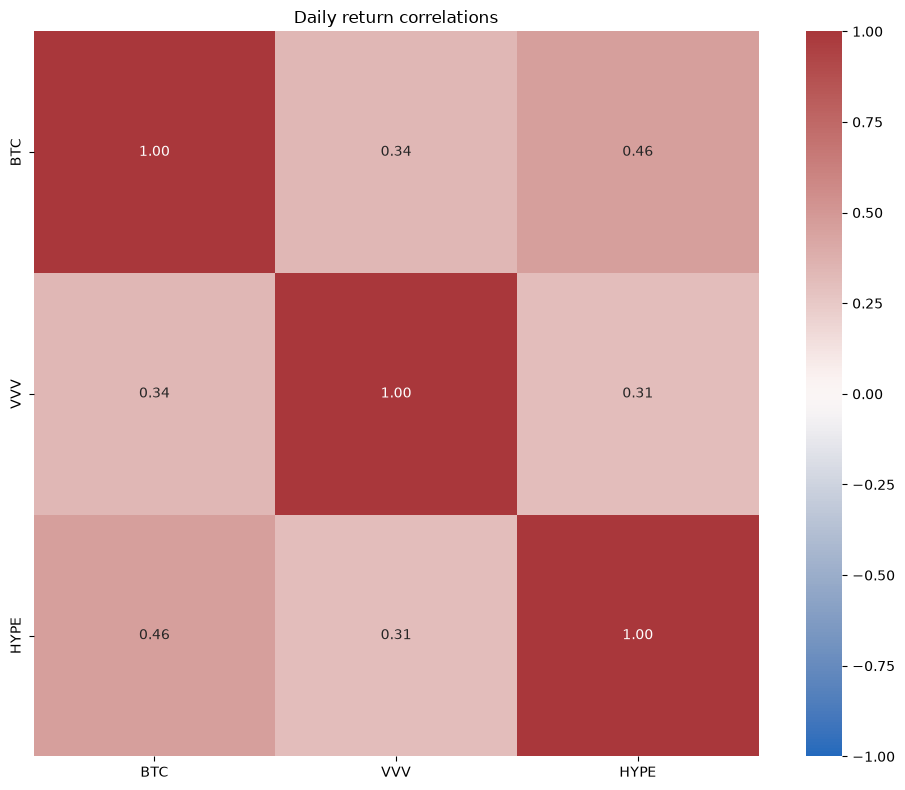

In [54]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0, square=True, ax=ax)
ax.set_title('Daily return correlations')
plt.tight_layout()
plt.show()

## Constrained full-Kelly portfolio

The optimizer maximizes historical daily log growth subject to the per-asset bounds, with any unallocated share held as cash. The chart, period returns, and performance metrics below all use these constrained full-Kelly weights.

In [55]:
MIN_FULL_KELLY_WEIGHT = 0.02
MAX_FULL_KELLY_WEIGHT = 0.15
RISK_FREE_ANNUAL = 0.05
TRADING_DAYS_PER_YEAR = 365
R = common_returns[ASSETS].to_numpy(dtype=float)
n_assets = len(ASSETS)
RISK_FREE_DAILY = (1 + RISK_FREE_ANNUAL) ** (1 / TRADING_DAYS_PER_YEAR) - 1


def project_weights(weights, lower, upper, budget=1.0):
    """Project weights onto box bounds with total allocation no greater than budget."""
    projected = np.clip(weights, lower, upper)
    if projected.sum() <= budget:
        return projected
    left = np.min(weights - upper) - 1.0
    right = np.max(weights - lower) + 1.0
    for _ in range(100):
        shift = (left + right) / 2.0
        projected = np.clip(weights - shift, lower, upper)
        if projected.sum() > budget:
            left = shift
        else:
            right = shift
    return np.clip(weights - right, lower, upper)


def optimize_full_kelly(returns, lower, upper, cash_daily_return, max_iterations=20000):
    """Maximize mean log growth with projected gradient descent using NumPy only."""
    def objective(weights):
        portfolio_returns = returns @ weights + (1.0 - weights.sum()) * cash_daily_return
        if np.any(portfolio_returns <= -1.0):
            return float('inf')
        return -np.log1p(portfolio_returns).mean()

    def gradient(weights):
        portfolio_returns = returns @ weights + (1.0 - weights.sum()) * cash_daily_return
        marginal_returns = returns - cash_daily_return
        return -(marginal_returns / (1.0 + portfolio_returns[:, None])).mean(axis=0)

    weights = project_weights(np.full(returns.shape[1], 1.0 / returns.shape[1]), lower, upper)
    step_size = 1.0
    for _ in range(max_iterations):
        current_value = objective(weights)
        current_gradient = gradient(weights)
        trial_step = step_size
        for _ in range(100):
            candidate = project_weights(weights - trial_step * current_gradient, lower, upper)
            direction = candidate - weights
            candidate_value = objective(candidate)
            upper_bound = current_value + current_gradient @ direction + (direction @ direction) / (2.0 * trial_step)
            if candidate_value <= upper_bound + 1e-14:
                break
            trial_step *= 0.5
        else:
            raise RuntimeError('Kelly optimizer could not find a stable step.')
        if np.max(np.abs(direction)) < 1e-10:
            return candidate
        weights = candidate
        step_size = min(trial_step * 1.2, 1e6)
    raise RuntimeError('Kelly optimizer did not converge within the iteration limit.')


full_kelly = pd.Series(
    optimize_full_kelly(R, MIN_FULL_KELLY_WEIGHT, MAX_FULL_KELLY_WEIGHT, RISK_FREE_DAILY),
    index=ASSETS,
    name='weight',
).sort_values(ascending=False)
full_portfolio = pd.concat([
    full_kelly,
    pd.Series({'Cash': 1.0 - full_kelly.sum()}, name='weight'),
])
print('Constrained full-Kelly weights, sorted by coin weight (%)')
display((100 * full_portfolio).rename('weight_pct').round(2).to_frame())


Constrained full-Kelly weights, sorted by coin weight (%)


,weight_pct
VVV,15.0
HYPE,15.0
BTC,2.0
Cash,68.0


## Constrained full-Kelly portfolio performance and risk metrics

Sharpe ratio, expected return, alpha, and historical volatility are calculated from daily portfolio returns; annualized metrics use 365 days per year. Historical 1-day VaR uses the empirical 5th and 1st return percentiles for 95% and 99% confidence, respectively. Dollar VaR is scaled to an initial $100 investment. Alpha is CAPM alpha versus BTC, and max drawdown is the largest peak-to-trough decline in compounded portfolio value.


### Calculate portfolio returns and performance

Apply the optimized weights, compare the portfolio with BTC, and calculate trailing returns, drawdown, and annualized risk and return metrics.

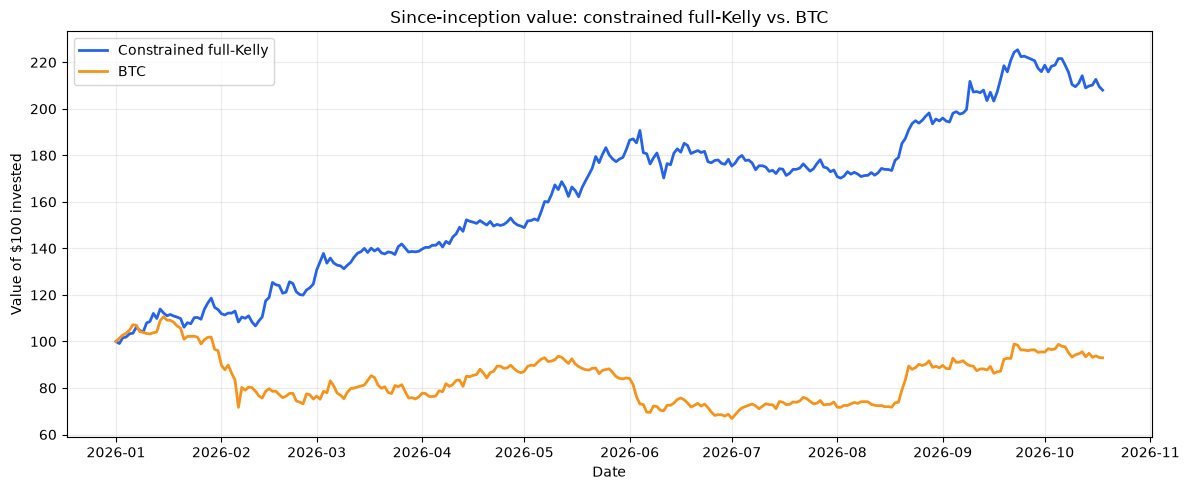

,Return
1D,-0.73%
7D,-1.43%
M (1 month),-2.18%
Q (3 months),20.75%
Since Inception,108.03%


,Daily return
Average daily return,0.27%
Largest daily gain,6.23%
Largest daily loss,-5.01%


Portfolio value shown from 2026-01-01 through 2026-10-18 (latest saved observation).


,All-Time High ($),Minimum Portfolio Value ($),Max Drawdown ($),Max Drawdown (%)
Since inception,$225.38,$99.10,-$20.48,-10.74%


,Sharpe,Beta,Alpha,Expected Return,Hist Vol (daily),Hist Vol (annualized),1D Hist VaR 95%,VaR 95% ($ / $100),1D Hist VaR 99%,VaR 99% ($ / $100),Risk-Free Rate,Max Drawdown
Constrained full-Kelly,2.989,0.335,93.46%,97.02%,1.61%,30.82%,2.35%,$2.35,3.38%,$3.38,5.00%,-10.74%


Benchmark: BTC; period: 2026-01-02 to 2026-10-18


In [56]:
BENCHMARK = 'BTC'
if BENCHMARK not in common_returns.columns:
    raise ValueError(f'Benchmark {BENCHMARK} is not in the return data.')

risky_weights = full_kelly.reindex(ASSETS).to_numpy()
portfolio_daily_returns = pd.Series(
    common_returns[ASSETS].to_numpy() @ risky_weights
    + full_portfolio.loc['Cash'] * RISK_FREE_DAILY,
    index=common_returns.index,
    name='Portfolio',
)
benchmark_returns = common_returns[BENCHMARK]
excess_returns = portfolio_daily_returns - RISK_FREE_DAILY
benchmark_excess = benchmark_returns - RISK_FREE_DAILY

beta = portfolio_daily_returns.cov(benchmark_returns) / benchmark_returns.var(ddof=1)
annualized_expected_return = portfolio_daily_returns.mean() * TRADING_DAYS_PER_YEAR
historical_vol_daily = portfolio_daily_returns.std(ddof=1)
annualized_volatility = historical_vol_daily * np.sqrt(TRADING_DAYS_PER_YEAR)
historical_var_95 = max(0.0, -portfolio_daily_returns.quantile(0.05))
historical_var_99 = max(0.0, -portfolio_daily_returns.quantile(0.01))
sharpe = (excess_returns.mean() / portfolio_daily_returns.std(ddof=1)) * np.sqrt(TRADING_DAYS_PER_YEAR)
alpha = (excess_returns.mean() - beta * benchmark_excess.mean()) * TRADING_DAYS_PER_YEAR
wealth = (1 + portfolio_daily_returns).cumprod()
initial_value = 100.0
initial_date = common_returns.index[0] - pd.Timedelta(days=1)
portfolio_value = pd.concat([
    pd.Series([initial_value], index=pd.DatetimeIndex([initial_date])),
    initial_value * wealth,
])
portfolio_value.name = 'Portfolio value ($)'
btc_wealth = (1 + benchmark_returns).cumprod()
btc_value = pd.concat([
    pd.Series([initial_value], index=pd.DatetimeIndex([initial_date])),
    initial_value * btc_wealth,
])
btc_value.name = 'BTC value ($)'

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(portfolio_value.index, portfolio_value, color='#2563eb', linewidth=2, label='Constrained full-Kelly')
ax.plot(btc_value.index, btc_value, color='#F7931A', linewidth=2, label='BTC')
ax.set_title('Since-inception value: constrained full-Kelly vs. BTC')
ax.set_ylabel('Value of $100 invested')
ax.set_xlabel('Date')
ax.grid(True, alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

as_of = portfolio_value.index[-1]
def trailing_return(days=None, months=None):
    target = as_of - (pd.DateOffset(months=months) if months is not None else pd.Timedelta(days=days))
    prior = portfolio_value.loc[portfolio_value.index <= target]
    if prior.empty:
        return np.nan
    return portfolio_value.iloc[-1] / prior.iloc[-1] - 1

period_returns = pd.Series({
    '1D': trailing_return(days=1),
    '7D': trailing_return(days=7),
    'M (1 month)': trailing_return(months=1),
    'Q (3 months)': trailing_return(months=3),
    'Since Inception': portfolio_value.iloc[-1] / 100 - 1
}, name='Return')
display(period_returns.to_frame().style.format('{:.2%}', na_rep='N/A'))
daily_return_summary = pd.Series({
    'Average daily return': portfolio_daily_returns.mean(),
    'Largest daily gain': portfolio_daily_returns.max(),
    'Largest daily loss': portfolio_daily_returns.min(),
}, name='Daily return')
display(daily_return_summary.to_frame().style.format('{:.2%}'))
print(f'Portfolio value shown from {portfolio_value.index[0].date()} through {as_of.date()} (latest saved observation).')
portfolio_peak = portfolio_value.cummax()
drawdown = portfolio_value / portfolio_peak - 1
drawdown_dollars = portfolio_value - portfolio_peak
max_drawdown = drawdown.min()
investment_summary = pd.Series({
    'All-Time High ($)': portfolio_value.max(),
    'Minimum Portfolio Value ($)': portfolio_value.min(),
    'Max Drawdown ($)': drawdown_dollars.min(),
    'Max Drawdown (%)': max_drawdown,
}, name='Since inception')
display(investment_summary.to_frame().T.style.format({
    'All-Time High ($)': '${:,.2f}',
    'Minimum Portfolio Value ($)': '${:,.2f}',
    'Max Drawdown ($)': lambda value: f'-${abs(value):,.2f}' if value < 0 else f'${value:,.2f}',
    'Max Drawdown (%)': '{:.2%}',
}))
risk_free_annual = (1 + RISK_FREE_DAILY) ** TRADING_DAYS_PER_YEAR - 1

performance_metrics = pd.DataFrame([{
    'Sharpe': sharpe,
    'Beta': beta,
    'Alpha': alpha,
    'Expected Return': annualized_expected_return,
    'Hist Vol (daily)': historical_vol_daily,
    'Hist Vol (annualized)': annualized_volatility,
    '1D Hist VaR 95%': historical_var_95,
    'VaR 95% ($ / $100)': historical_var_95 * 100,
    '1D Hist VaR 99%': historical_var_99,
    'VaR 99% ($ / $100)': historical_var_99 * 100,
    'Risk-Free Rate': risk_free_annual,
    'Max Drawdown': max_drawdown,
}], index=['Constrained full-Kelly'])
display(performance_metrics.style.format({
    'Sharpe': '{:.3f}', 'Beta': '{:.3f}', 'Alpha': '{:.2%}',
    'Expected Return': '{:.2%}',
    'Hist Vol (daily)': '{:.2%}', 'Hist Vol (annualized)': '{:.2%}',
    '1D Hist VaR 95%': '{:.2%}', 'VaR 95% ($ / $100)': '${:,.2f}',
    '1D Hist VaR 99%': '{:.2%}', 'VaR 99% ($ / $100)': '${:,.2f}',
    'Risk-Free Rate': '{:.2%}', 'Max Drawdown': '{:.2%}',
}))
print(f'Benchmark: {BENCHMARK}; period: {common_returns.index.min().date()} to {common_returns.index.max().date()}')

## CoinGecko factor model

CoinGecko historical market charts provide prices, market capitalization, and 24-hour volume rather than ready-made factor returns ([API reference](https://docs.coingecko.com/reference/coins-id-market-chart-range)). This notebook builds factors from those data for the selected asset universe: Bitcoin market excess return and cap-weighted altcoin return minus BTC. With at least four selected altcoins, it also builds small-minus-large market-cap, 30-day momentum winner-minus-loser, and high-minus-low turnover (volume/market cap) spreads. Characteristics are lagged to avoid using same-day information. The output shows each factor beta, Newey-West t-statistic, annualized factor premium and estimated portfolio return contribution, plus model R-squared and alpha. The estimates are descriptive and specific to this asset universe.


In [ ]:
# CoinGecko factor model for portfolio excess returns.
from pathlib import Path

MARKET_DATA_FILE = Path('data') / 'crypto_market_data.csv'
if not MARKET_DATA_FILE.exists():
    raise FileNotFoundError(
        f'Missing {MARKET_DATA_FILE}. Run the CoinGecko refresh cell first to fetch market-cap and volume history.'
    )

market_data = pd.read_csv(MARKET_DATA_FILE, parse_dates=['date'])
market_data['date'] = pd.to_datetime(market_data['date'], utc=True).dt.normalize()
market_data = market_data.set_index('date').sort_index()

market_caps = pd.DataFrame(index=common_returns.index)
trading_volumes = pd.DataFrame(index=common_returns.index)
for asset in ASSETS:
    cap_col = f'{asset}_market_cap'
    volume_col = f'{asset}_volume'
    if cap_col not in market_data.columns or volume_col not in market_data.columns:
        raise ValueError(f'Market-cap/volume history is missing for {asset}; rerun the CoinGecko refresh cell.')
    market_caps[asset] = pd.to_numeric(market_data[cap_col], errors='coerce').reindex(common_returns.index).ffill(limit=2)
    trading_volumes[asset] = pd.to_numeric(market_data[volume_col], errors='coerce').reindex(common_returns.index).ffill(limit=2)

alt_assets = [asset for asset in ASSETS if asset != 'BTC']
lagged_caps = market_caps.shift(1)
alt_cap_weights = lagged_caps[alt_assets].div(lagged_caps[alt_assets].sum(axis=1), axis=0)
alt_market_return = (common_returns[alt_assets] * alt_cap_weights).sum(axis=1, min_count=len(alt_assets))


def long_short_factor(signal, asset_returns, long_low=False):
    """Build an equal-weight long-short spread from lagged cross-sectional signals."""
    factor = pd.Series(np.nan, index=asset_returns.index, dtype=float)
    for date in asset_returns.index:
        available = signal.loc[date].dropna().index.intersection(asset_returns.columns)
        if len(available) < 4:
            continue
        ranked = signal.loc[date, available].sort_values()
        group_size = len(ranked) // 2
        if long_low:
            long_assets, short_assets = ranked.index[:group_size], ranked.index[-group_size:]
        else:
            long_assets, short_assets = ranked.index[-group_size:], ranked.index[:group_size]
        daily_returns = asset_returns.loc[date]
        factor.loc[date] = daily_returns[long_assets].mean() - daily_returns[short_assets].mean()
    return factor


factor_returns = pd.DataFrame(index=common_returns.index)
factor_returns['BTC market excess'] = common_returns['BTC'] - RISK_FREE_DAILY
if alt_assets:
    factor_returns['Alt market - BTC'] = alt_market_return - common_returns['BTC']

# Long-short cross-sectional spreads need enough altcoins to form meaningful groups.
# With fewer than four alts, keep the market factors and omit these unavailable spreads.
if len(alt_assets) >= 4:
    lagged_momentum = prices[alt_assets].pct_change(30).shift(1).reindex(common_returns.index)
    turnover_ratio = trading_volumes[alt_assets].div(
        market_caps[alt_assets].where(market_caps[alt_assets] > 0)
    )
    lagged_turnover = turnover_ratio.shift(1).rolling(30, min_periods=20).mean()
    factor_returns['Small - large'] = long_short_factor(
        lagged_caps[alt_assets], common_returns[alt_assets], long_low=True
    )
    factor_returns['Momentum'] = long_short_factor(
        lagged_momentum, common_returns[alt_assets]
    )
    factor_returns['High - low turnover'] = long_short_factor(
        lagged_turnover, common_returns[alt_assets]
    )
else:
    print(
        f'Skipping size, momentum, and turnover spreads: {len(alt_assets)} selected altcoins; '
        'at least 4 are needed.'
    )

def normalize_daily_index(data):
    """Align daily Series/DataFrames on UTC dates and collapse duplicate dates."""
    normalized = data.copy()
    normalized.index = pd.to_datetime(normalized.index, utc=True).normalize()
    return normalized.groupby(level=0, sort=True).last()


# Factor and portfolio series can come from notebook cells run at different times.
# Normalize both indexes before joining so timezone/time-of-day differences do not
# turn otherwise matching observations into an empty intersection.
factor_returns = normalize_daily_index(factor_returns)
portfolio_excess_returns = normalize_daily_index(
    (portfolio_daily_returns - RISK_FREE_DAILY).rename('Portfolio excess')
)
model_data = pd.concat([portfolio_excess_returns, factor_returns], axis=1)
model_data = model_data.replace([np.inf, -np.inf], np.nan).dropna()
if len(model_data) < 60:
    raise ValueError(
        f'Factor model has only {len(model_data)} complete aligned daily observations; at least 60 are required. '
        'Confirm that the portfolio metrics and factor cells were run using the same saved price history.'
    )

factor_names = list(factor_returns.columns)
y = model_data['Portfolio excess'].to_numpy(dtype=float)
X = np.column_stack([np.ones(len(model_data)), model_data[factor_names].to_numpy(dtype=float)])
coefficients, _, rank, _ = np.linalg.lstsq(X, y, rcond=None)
if rank < X.shape[1]:
    raise ValueError('Factor model is rank-deficient; check factor correlations or history coverage.')
residuals = y - X @ coefficients
r_squared = 1.0 - (residuals @ residuals) / np.sum((y - y.mean()) ** 2)
adjusted_r_squared = 1.0 - (1.0 - r_squared) * (len(y) - 1) / (len(y) - X.shape[1])

# Newey-West HAC standard errors with a 7-day lag for daily observations.
scores = X * residuals[:, None]
meat = scores.T @ scores
hac_lags = min(7, len(y) - 1)
for lag in range(1, hac_lags + 1):
    weight = 1.0 - lag / (hac_lags + 1.0)
    cross_products = scores[lag:].T @ scores[:-lag]
    meat += weight * (cross_products + cross_products.T)
bread = np.linalg.pinv(X.T @ X)
hac_covariance = bread @ meat @ bread
standard_errors = np.sqrt(np.maximum(np.diag(hac_covariance), 0.0))
t_statistics = np.divide(
    coefficients, standard_errors,
    out=np.full_like(coefficients, np.nan), where=standard_errors > 0,
)

factor_premiums_annual = model_data[factor_names].mean() * TRADING_DAYS_PER_YEAR
factor_contributions_annual = pd.Series(coefficients[1:], index=factor_names) * factor_premiums_annual
factor_model_summary = pd.DataFrame({
    'Beta': coefficients[1:],
    'HAC t-stat': t_statistics[1:],
    'Factor premium (%/yr)': factor_premiums_annual,
    'Portfolio contribution (%/yr)': factor_contributions_annual,
}, index=factor_names)
factor_model_summary.loc['Alpha'] = [
    np.nan,
    t_statistics[0],
    np.nan,
    coefficients[0] * TRADING_DAYS_PER_YEAR,
]
factor_model_fit = pd.Series({
    'Observations': len(model_data),
    'R-squared': r_squared,
    'Adjusted R-squared': adjusted_r_squared,
    'Annual alpha': coefficients[0] * TRADING_DAYS_PER_YEAR,
    'BTC beta (factor model)': coefficients[1],
    'BTC beta (single factor)': beta,
}, name='Factor model fit')

print(
    f'Factor model: R²={r_squared:.1%} | adjusted R²={adjusted_r_squared:.1%} | '
    f'annual alpha={coefficients[0] * TRADING_DAYS_PER_YEAR:.2%} | '
    f'n={len(model_data)} days'
)
print(
    f'Single-factor BTC beta={beta:.3f} | factor-model BTC beta='
    f'{factor_model_summary.loc["BTC market excess", "Beta"]:.3f}'
)
display(factor_model_summary.style.format({
    'Beta': '{:.3f}', 'HAC t-stat': '{:.2f}',
    'Factor premium (%/yr)': '{:.2%}',
    'Portfolio contribution (%/yr)': '{:+.2%}',
}, na_rep='—'))
display(factor_model_fit.to_frame())


### Save analysis outputs

Write refreshed prices and market data, return series, correlations, optimized weights, portfolio metrics, and factor-model estimates to CSV files in `data/`.


In [ ]:
from pathlib import Path
DATA_DIR = Path('data')
DATA_DIR.mkdir(parents=True, exist_ok=True)
correlation.to_csv(DATA_DIR / 'crypto_return_correlation.csv')
full_portfolio.to_csv(DATA_DIR / 'crypto_kelly_full_weights.csv', header=True)
full_portfolio.to_csv(DATA_DIR / 'crypto_kelly_weights.csv', header=True)
performance_metrics.to_csv(DATA_DIR / 'crypto_portfolio_metrics.csv')
portfolio_daily_returns.to_csv(DATA_DIR / 'crypto_portfolio_daily_returns.csv', header=True)
prices.to_csv(DATA_DIR / 'crypto_daily_prices_usd.csv')
market_data.reset_index().to_csv(DATA_DIR / 'crypto_market_data.csv', index=False)
common_returns.to_csv(DATA_DIR / 'crypto_daily_returns.csv')
factor_model_summary.to_csv(DATA_DIR / 'crypto_portfolio_factor_model.csv')
factor_model_fit.to_csv(DATA_DIR / 'crypto_portfolio_factor_fit.csv')
factor_returns.to_csv(DATA_DIR / 'crypto_factor_returns.csv')
print('Saved portfolio, factor, market data, and return outputs to data/.')

Saved portfolio, factor, market data, and return outputs to data/.
